# ITRI625 Context-Aware Phishing Email Detection

Primary Jupyter training workflow using the Kaggle phishing-email dataset. The model uses word unigrams, bigrams and trigrams plus email-level structural features: URL count, urgency, credential requests, call-to-action language, money terms, punctuation, character ratios and message length.

In [1]:
from pathlib import Path
import json, copy, joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss, classification_report, ConfusionMatrixDisplay, precision_recall_curve, roc_curve
from sklearn.model_selection import train_test_split
from features import build_features, STRUCTURAL_FEATURE_NAMES
RANDOM_STATE=42
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
DATA_DIR,MODEL_DIR,ARTIFACT_DIR=ROOT/'data',ROOT/'models',ROOT/'artifacts'
for folder in (DATA_DIR,MODEL_DIR,ARTIFACT_DIR): folder.mkdir(exist_ok=True)
DATA_PATH=DATA_DIR/'phishing_email.csv'
assert DATA_PATH.exists(), f'Place the extracted Kaggle CSV at {DATA_PATH}'

## 1. Load and inspect the Kaggle dataset

In [2]:
df=pd.read_csv(DATA_PATH)
display(df.head())
print('Rows and columns:',df.shape)
display(df['label'].value_counts().rename(index={0:'Legitimate',1:'Phishing'}))

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


Rows and columns: (82486, 2)


label
Phishing      42891
Legitimate    39595
Name: count, dtype: int64

## 2. Split data and construct context-aware features

In [3]:
texts=df['text_combined'].fillna('').astype(str)
labels=pd.to_numeric(df['label'],errors='raise').astype(int).to_numpy()
X_train,X_temp,y_train,y_temp=train_test_split(texts,labels,test_size=.30,stratify=labels,random_state=RANDOM_STATE)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=.50,stratify=y_temp,random_state=RANDOM_STATE)
pd.DataFrame({'text':X_test,'label':y_test}).to_csv(ARTIFACT_DIR/'test_set.csv',index=False)
vectorizer=TfidfVectorizer(lowercase=True,strip_accents='unicode',ngram_range=(1,3),min_df=3,max_features=20000,sublinear_tf=True)
X_train_v=build_features(vectorizer,X_train,fit=True)
X_val_v,X_test_v=build_features(vectorizer,X_val),build_features(vectorizer,X_test)
print({'train':len(X_train),'validation':len(X_val),'test':len(X_test)})
print('Context-aware feature count:',X_train_v.shape[1])

{'train': 57740, 'validation': 12373, 'test': 12373}
Context-aware feature count: 20012


## 3. Train with validation metrics and patience-based early stopping

In [4]:
def evaluate(model,X,y):
    pred,prob=model.predict(X),model.predict_proba(X)[:,1]
    return {'accuracy':accuracy_score(y,pred),'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0),'roc_auc':roc_auc_score(y,prob),'loss':log_loss(y,model.predict_proba(X),labels=[0,1])}
model=SGDClassifier(loss='log_loss',alpha=1e-5,average=True,random_state=RANDOM_STATE)
history=[]; best_model=None; best_f1=-1; best_epoch=0; stale=0; patience=5
for epoch in range(1,31):
    order=np.random.default_rng(RANDOM_STATE+epoch).permutation(X_train_v.shape[0])
    model.partial_fit(X_train_v[order],y_train[order],classes=np.array([0,1]))
    metrics=evaluate(model,X_val_v,y_val); row={'epoch':epoch,**metrics}; history.append(row); print(row)
    if metrics['f1']>best_f1+1e-4: best_f1,best_epoch,best_model,stale=metrics['f1'],epoch,copy.deepcopy(model),0
    else: stale+=1
    if stale>=patience: print('Early stopping at epoch',epoch); break
history_df=pd.DataFrame(history); display(history_df)

{'epoch': 1, 'accuracy': 0.9797138931544492, 'precision': 0.9798230637901598, 'recall': 0.9811936586882188, 'f1': 0.9805078822707153, 'roc_auc': 0.9960816796481773, 'loss': 0.07542300136883612}
{'epoch': 2, 'accuracy': 0.9831083811525095, 'precision': 0.9818857408267534, 'recall': 0.9857009636307118, 'f1': 0.9837896533002405, 'roc_auc': 0.9973878823892037, 'loss': 0.057125864015999075}


{'epoch': 3, 'accuracy': 0.984078234866241, 'precision': 0.9829642248722317, 'recall': 0.986478085172521, 'f1': 0.9847180203242573, 'roc_auc': 0.9978828639295902, 'loss': 0.05264448786304384}
{'epoch': 4, 'accuracy': 0.9851289097227834, 'precision': 0.9838959430164137, 'recall': 0.9875660553310538, 'f1': 0.9857275829972075, 'roc_auc': 0.9982558665675901, 'loss': 0.05077181114586194}


{'epoch': 5, 'accuracy': 0.9844823405802958, 'precision': 0.9843265052762259, 'recall': 0.9858563879390737, 'f1': 0.985090852616866, 'roc_auc': 0.998119886654095, 'loss': 0.053102806253464814}
{'epoch': 6, 'accuracy': 0.9833508445809424, 'precision': 0.983690587138863, 'recall': 0.9843021448554554, 'f1': 0.9839962709757614, 'roc_auc': 0.9979872565152199, 'loss': 0.05555772852979966}


{'epoch': 7, 'accuracy': 0.9844015194374849, 'precision': 0.984474460487502, 'recall': 0.98554553932235, 'f1': 0.9850097087378641, 'roc_auc': 0.9982314498510212, 'loss': 0.05386768015398159}
{'epoch': 8, 'accuracy': 0.9838357714378081, 'precision': 0.9840062111801242, 'recall': 0.9849238420889027, 'f1': 0.9844648128009943, 'roc_auc': 0.9981971408312768, 'loss': 0.05502803784641247}


{'epoch': 9, 'accuracy': 0.9842398771518629, 'precision': 0.9841688654353562, 'recall': 0.98554553932235, 'f1': 0.9848567212860139, 'roc_auc': 0.9983552344912892, 'loss': 0.054019927633592514}
Early stopping at epoch 9


,epoch,accuracy,precision,recall,f1,roc_auc,loss
0,1,0.979714,0.979823,0.981194,0.980508,0.996082,0.075423
1,2,0.983108,0.981886,0.985701,0.983790,0.997388,0.057126
2,3,0.984078,0.982964,0.986478,0.984718,0.997883,0.052644
3,4,0.985129,0.983896,0.987566,0.985728,0.998256,0.050772
4,5,0.984482,0.984327,0.985856,0.985091,0.998120,0.053103
5,6,0.983351,0.983691,0.984302,0.983996,0.997987,0.055558
6,7,0.984402,0.984474,0.985546,0.985010,0.998231,0.053868
7,8,0.983836,0.984006,0.984924,0.984465,0.998197,0.055028
8,9,0.984240,0.984169,0.985546,0.984857,0.998355,0.054020


## 4. Validation evaluation, manual test-set inspection and final test metrics

In [5]:
validation_metrics=evaluate(best_model,X_val_v,y_val); display(pd.DataFrame(validation_metrics,index=['validation']).T)
sample_size=20
manual_sample=pd.DataFrame({'email_text':X_test.reset_index(drop=True),'actual_label':y_test}).sample(n=sample_size,random_state=RANDOM_STATE).reset_index(drop=True)
sample_features=build_features(vectorizer,manual_sample['email_text'])
manual_sample['predicted_label']=best_model.predict(sample_features); manual_sample['phishing_probability']=best_model.predict_proba(sample_features)[:,1].round(4)
manual_sample['actual']=manual_sample['actual_label'].map({0:'Legitimate',1:'Phishing'}); manual_sample['predicted']=manual_sample['predicted_label'].map({0:'Legitimate',1:'Phishing'}); manual_sample['correct']=manual_sample['actual_label']==manual_sample['predicted_label']
display(manual_sample[['email_text','actual','predicted','phishing_probability','correct']])
test_metrics=evaluate(best_model,X_test_v,y_test); display(pd.DataFrame(test_metrics,index=['test']).T)
print(classification_report(y_test,best_model.predict(X_test_v),target_names=['Legitimate','Phishing'],zero_division=0))

,validation
accuracy,0.985129
precision,0.983896
recall,0.987566
f1,0.985728
roc_auc,0.998256
loss,0.050772


,email_text,actual,predicted,phishing_probability,correct
0,iso 8859 1 q aten e 7 e 3 distribuidores de ha...,Phishing,Phishing,0.9847,True
1,messner arcady_1963printplusnl high passion zo...,Phishing,Phishing,0.9926,True
2,lori nadeau dpdioxidebejedcom offer medication...,Phishing,Phishing,0.9995,True
3,perfect logo charset koi 8 r thinking breathin...,Phishing,Phishing,0.9981,True
4,lara souza laraceoagde real gentlemen fair lad...,Phishing,Phishing,0.9924,True
5,update prc process please read attached memo s...,Legitimate,Legitimate,0.0000,True
6,konstantin veretennicov nmiqoucicjfvsgmailcom ...,Legitimate,Legitimate,0.0003,True
7,hudson hudsonnetcnctnet _ _ _ _ _ _ _ _ _ _ _ ...,Phishing,Phishing,0.9968,True
8,andrew dalke jmuuqdalkescientificcom home page...,Legitimate,Legitimate,0.0009,True
9,mouss qpeqrnetoyennet andrea wrote recently in...,Legitimate,Legitimate,0.0012,True


,test
accuracy,0.986503
precision,0.986793
recall,0.987253
f1,0.987023
roc_auc,0.997773
loss,0.052725


              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99      5940
    Phishing       0.99      0.99      0.99      6433

    accuracy                           0.99     12373
   macro avg       0.99      0.99      0.99     12373
weighted avg       0.99      0.99      0.99     12373



## 5. Required graphs and contextual explanations

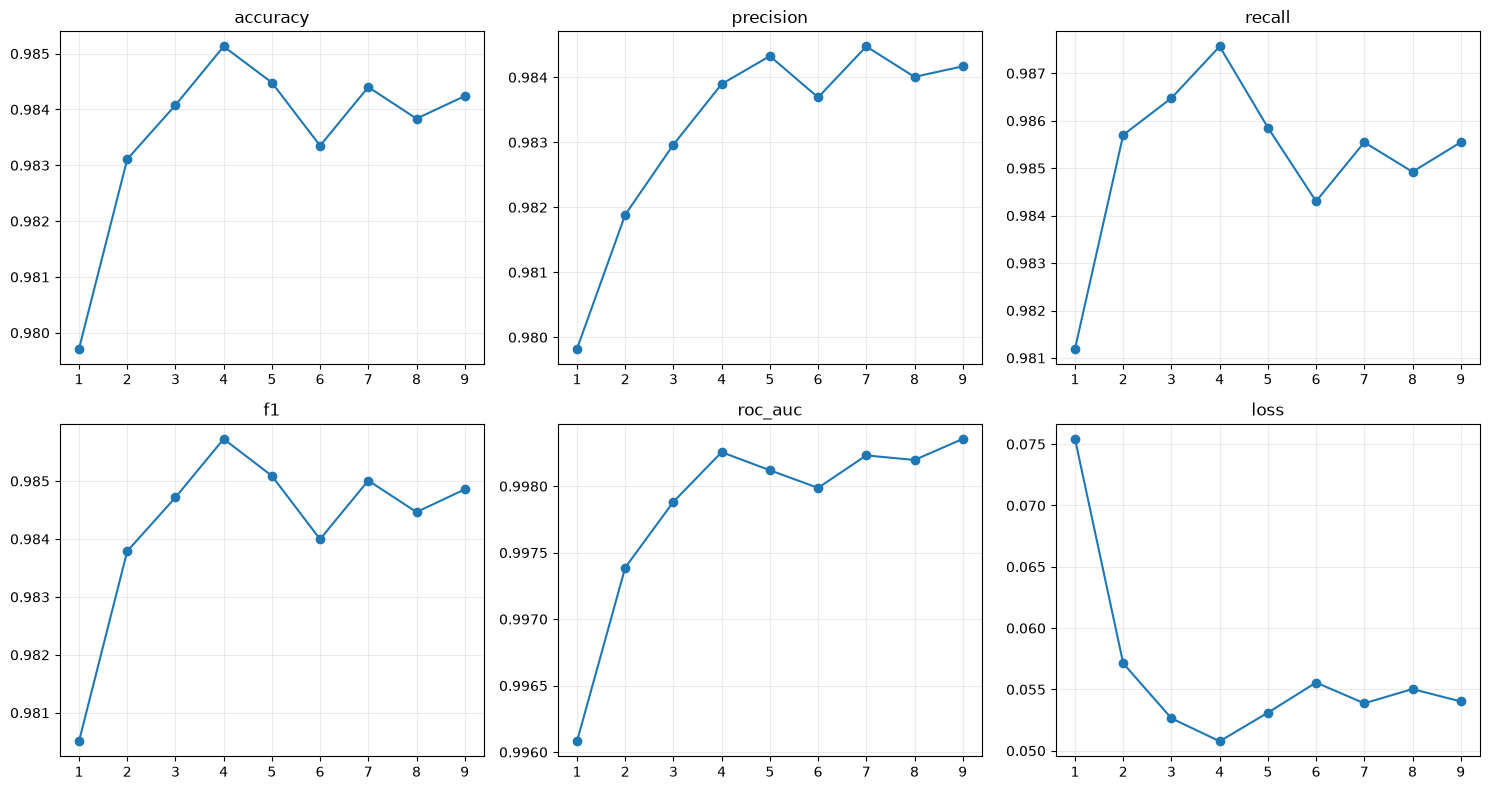

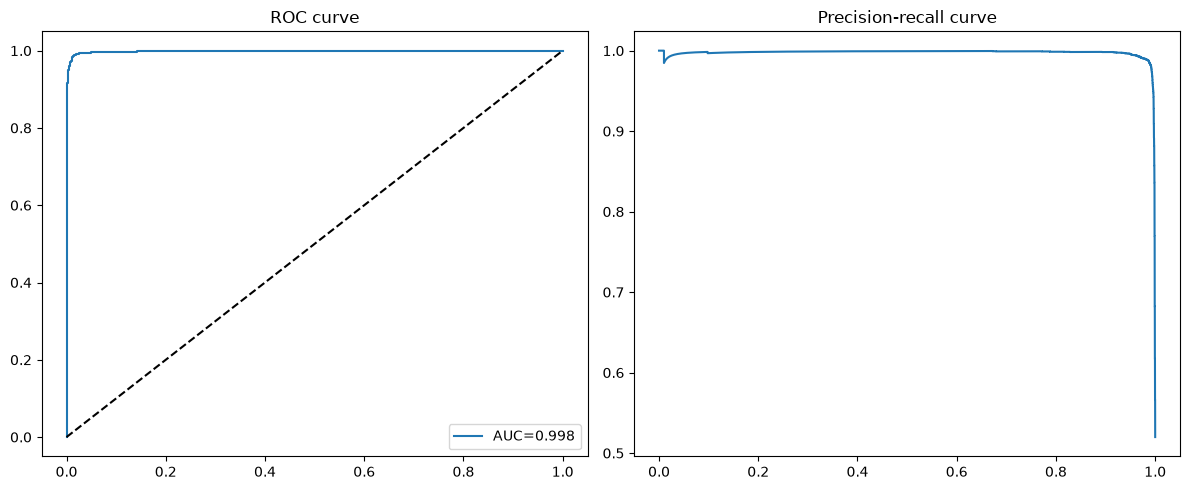

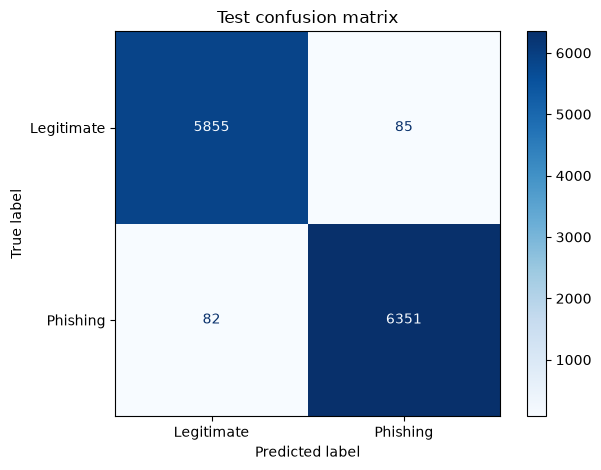

Most phishing-associated context features: [np.str_('click'), np.str_('immediately'), np.str_('josemonkeyorg'), np.str_('2004'), np.str_('money'), np.str_('0300'), np.str_('2005'), np.str_('urgent'), np.str_('life'), np.str_('2016'), np.str_('com'), np.str_('http'), np.str_('country'), np.str_('love'), np.str_('remove'), np.str_('investment'), np.str_('reply'), np.str_('2017'), np.str_('monkeyorg'), np.str_('dear')]
Most legitimate-associated context features: [np.str_('enron'), np.str_('wrote'), np.str_('thanks'), np.str_('university'), np.str_('vince'), np.str_('opensuse'), np.str_('louise'), np.str_('im'), np.str_('ierant'), np.str_('password'), np.str_('language'), np.str_('february'), np.str_('pm'), np.str_('2001'), np.str_('fork'), np.str_('1300'), np.str_('questions'), np.str_('list'), np.str_('energy'), np.str_('houston')]


In [6]:
fig,axes=plt.subplots(2,3,figsize=(15,8))
for ax,metric in zip(axes.ravel(),['accuracy','precision','recall','f1','roc_auc','loss']): ax.plot(history_df.epoch,history_df[metric],marker='o'); ax.set_title(metric); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(ARTIFACT_DIR/'training_metrics.png',dpi=160); display(fig); plt.close(fig)
prob=best_model.predict_proba(X_test_v)[:,1]; fpr,tpr,_=roc_curve(y_test,prob); precision,recall,_=precision_recall_curve(y_test,prob)
fig,axes=plt.subplots(1,2,figsize=(12,5)); axes[0].plot(fpr,tpr,label=f'AUC={roc_auc_score(y_test,prob):.3f}'); axes[0].plot([0,1],[0,1],'k--'); axes[0].legend(); axes[0].set_title('ROC curve'); axes[1].plot(recall,precision); axes[1].set_title('Precision-recall curve'); fig.tight_layout(); fig.savefig(ARTIFACT_DIR/'roc_pr_curves.png',dpi=160); display(fig); plt.close(fig)
ConfusionMatrixDisplay.from_predictions(y_test,best_model.predict(X_test_v),display_labels=['Legitimate','Phishing'],cmap='Blues',values_format='d'); plt.title('Test confusion matrix'); plt.tight_layout(); plt.savefig(ARTIFACT_DIR/'confusion_matrix.png',dpi=160); plt.show()
feature_names=np.asarray(list(vectorizer.get_feature_names_out())+STRUCTURAL_FEATURE_NAMES); weights=best_model.coef_[0]
print('Most phishing-associated context features:',list(feature_names[np.argsort(weights)[-20:][::-1]]))
print('Most legitimate-associated context features:',list(feature_names[np.argsort(weights)[:20]]))

## 6. Export the context-aware model for the API and GUI

In [7]:
joblib.dump({'vectorizer':vectorizer,'model':best_model,'label_names':{0:'Legitimate',1:'Phishing'},'structural_feature_names':STRUCTURAL_FEATURE_NAMES},MODEL_DIR/'phishing_model.joblib')
history_df.to_csv(ARTIFACT_DIR/'metrics.csv',index=False)
results={'dataset_rows':len(df),'split_sizes':{'train':len(X_train),'validation':len(X_val),'test':len(X_test)},'best_epoch':best_epoch,'stopped_after_epoch':len(history_df),'patience':patience,'test_metrics':{k:float(v) for k,v in test_metrics.items()},'context_features':['word_unigrams_bigrams_trigrams']+STRUCTURAL_FEATURE_NAMES}
(ARTIFACT_DIR/'results.json').write_text(json.dumps(results,indent=2)); display(results)

{'dataset_rows': 82486,
 'split_sizes': {'train': 57740, 'validation': 12373, 'test': 12373},
 'best_epoch': 4,
 'stopped_after_epoch': 9,
 'patience': 5,
 'test_metrics': {'accuracy': 0.9865028691505698,
  'precision': 0.9867930391547545,
  'recall': 0.9872532255557283,
  'f1': 0.987023078716295,
  'roc_auc': 0.9977731875990852,
  'loss': 0.05272530144751428},
 'context_features': ['word_unigrams_bigrams_trigrams',
  'email_length_log',
  'word_count_log',
  'url_count',
  'exclamation_count',
  'question_count',
  'digit_ratio',
  'uppercase_ratio',
  'urgency_terms',
  'credential_terms',
  'call_to_action_terms',
  'money_terms',
  'html_markers']}

The desktop app uses this exported context-aware model. It also provides XAI by showing influential contextual features and structural signals for each prediction.

![Training metrics](../artifacts/training_metrics.png)

![ROC and precision-recall curves](../artifacts/roc_pr_curves.png)

![Confusion matrix](../artifacts/confusion_matrix.png)